# 外部冲击 × 内部脆弱度：事件检验与 PQD 关联检验

分析日期：2026-10-06。主分析截止 2026Q2。业务口径：**FICC/GSD、FICC/MBSD 分开；NSCC 代表 ECS 清算侧，DTC 不混入**。

## 主要发现

- 7 个日度候选中，4 个通过预设的历史事件初筛。MOVE 的完整可用历史尚未取得，国债收益率波动是独立候选。
- GSD、MBSD 没有候选同时通过事件初筛和历史筛选期的下一季度 PQD 正方向相关门槛。
- NSCC 的原始/校正 SOFR−EFFR 对下一季度支付义务/已量化资源比的筛选期 Spearman 为 0.355 / 0.332，但区间跨零，不能视为稳定业务影响证据。
- **直接相乘并没有得到稳定验证**：NSCC 校正资金利差的乘积指标在后续 6 季度中相关为 −0.143；它只是研究指标，不是损失概率。

本 notebook 会从本文件夹冻结的原始输入重算，保存全部明细。原来的分析、中文和英文文件保留。

## 方法与口径

先按经济机制固定风险通道，再检验，不根据最大相关系数重新定义通道。资金→支付义务/已量化资源；利率、信用→超过初始保证金的 Cover1 压力损失/期末初始保证金；VIX 对 NSCC 属股市通道，对 FICC 仅属辅助情绪；国债利率对 NSCC 仅作辅助交叉市场观察。

### 关键假设

1. 报警：高于此前 252 个有效观察日的第 90 百分位，至少 126 个历史值。阈值排除当天，等于阈值不报警。
2. 事件初筛：至少 2 个对应通道的历史事件；至少 2/3 被捕捉；事件内报警天数比例的中位数 ≥25%；非指定事件期间报警率 ≤15%。后两个具体数值是本轮分析者设定，不是 DTCC 标准。
3. 非指定事件期间排除四个事件窗口及前后 20 个工作日；期间仍可能有其他压力，**不是已核实的真实误报率**。
4. 每季度取候选日度值最大值，至少 45 个有效值；与下一**日历季度** PQD 配对。方向必须为正，rho ≥0.3 且至少 12 对有效季度。
5. 筛选期按 PQD 结果截至 2024Q4；2025Q1–2026Q2 为后续描述性验证（6 期）。2025 年事件不参与历史事件筛选。已知事件是用户指定的历史案例，不能称为真正盲测。
6. 2020Q4–2026Q2 共 23 份季度报告，2024Q4 由 PDF 补齐；2022Q1 资源部分空白，资金比值保留缺失。2019、2020 年冲击当时的对应 PQD 不在本次取得的历史范围。
7. 4.4.3 是**超过初始保证金的压力损失**，且可能是最大 Cover1 比率当日的损失，不是实际损失或最大总损失。很多数值覆盖过去 12 个月；t+1 的 T12m 窗口包含 t，不能当作独立未来损失。
8. 7.1 分母只汇总已量化的合格资源。FICC 含会员 CCLF 承诺，7.1.9 的抵押品后来为 N/A；不能把比值 >1 解释为真实资金缺口。另看 7.3.2 实际覆盖不足天数和可比现金+承诺资源敏感性。

参数冻结在 `analysis_plan.json`。下文同季度、分子/分母分解、乘积比较是看到初筛结果后的解释性诊断，不改变初筛规则。

In [1]:
from pathlib import Path
import sys, os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'analysis_plan.json').exists():
    ROOT = Path('risk_business_ml/event_vulnerability_tests_2026_10_06').resolve()
assert (ROOT / 'analysis_plan.json').exists(), '请从 notebook 所在目录运行，保留 raw/data/src 文件夹。'
sys.path.insert(0, str(ROOT / 'src'))
import run_analysis as analysis
plt.rcParams.update({'figure.dpi':125, 'font.family':'DejaVu Sans','font.size':11,
    'axes.spines.top':False, 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
from IPython.display import display
plan = json.loads((ROOT/'analysis_plan.json').read_text())
display(pd.DataFrame(analysis.METRICS)[['indicator','channel','unit','transform']])

,indicator,channel,unit,transform
0,sofr_effr,funding,bp,(SOFR−EFFR)*100
1,sofr_effr_adjusted,funding,bp,subtract strictly past calendar-group median; ...
2,ust10_abs_change,rates,bp,absolute change between consecutive available ...
3,ust10_rv20,rates,bp/day,20-observation standard deviation of daily yie...
4,baa_spread,credit,bp,"BAA10Y*100; yield spread, not option-adjusted ..."
5,baa_widen20,credit,bp,positive part of 20-available-observation cred...
6,vix,equity,index points,"level; primary equity-market signal for NSCC, ..."


## 数据与质量检查

原始文件有 SHA-256 校验。XLSX 按实体标签定位，选取“Total”所在行，区分均值/峰值子项；百分数统一为 0–1。PDF 金额为百万美元，乘以 1,000,000；2024Q4 原页已渲染核对。空白、N/A 与零分别保留，日度数据不前向填充。

In [2]:
pqd = analysis.read_pqd()
daily = analysis.load_daily()
display(pqd.groupby('entity').agg(quarters=('quarter','size'),first=('quarter','min'),last=('quarter','max'),valid_resources=('qlr_quantified_sum_usd','count')))
display(pqd[pqd.quarter=='2026Q2'][['entity','stress_loss_to_im','payment_to_qlr','top5_open_share','liquidity_breach_days']].round(4))

,quarters,first,last,valid_resources
entity,,,,
GSD,23,2020Q4,2026Q2,22
MBSD,23,2020Q4,2026Q2,22
NSCC,23,2020Q4,2026Q2,22


,entity,stress_loss_to_im,payment_to_qlr,top5_open_share,liquidity_breach_days
66,GSD,0.0402,0.6878,0.2655,0.0
67,MBSD,0.2483,0.4448,0.5063,0.0
68,NSCC,0.0535,1.1782,0.3649,0.0


## 检验一：压力事件能否报警

每个图保留独立单位，不比较跨指标的绝对高度。橙色区间为预设事件窗口，虚线为只使用过去数据的报警阈值。四个事件分别绘图，防止 2019 年 295bp 峰值遮住其他事件。

In [3]:
event_detail, event_screen = analysis.event_tests(daily)
display(event_screen[['indicator','relevant_training_events','event_hit_fraction','median_event_alarm_fraction','train_non_event_alarm_proxy','event_status']].round(3))
display(event_detail[event_detail.event=='treasury_2025'][['indicator','event_hit','alarm_day_fraction','event_peak']].round(3))

,indicator,relevant_training_events,event_hit_fraction,median_event_alarm_fraction,train_non_event_alarm_proxy,event_status
0,sofr_effr,3,1.0,0.375,0.096,PASS
1,sofr_effr_adjusted,3,1.0,0.250,0.103,PASS
2,ust10_abs_change,2,1.0,0.568,0.106,PASS
3,ust10_rv20,2,0.5,0.500,0.088,FAIL
4,baa_spread,2,0.5,0.500,0.117,FAIL
5,baa_widen20,2,1.0,0.750,0.111,PASS
6,vix,2,0.5,0.500,0.092,FAIL


,indicator,event_hit,alarm_day_fraction,event_peak
3,sofr_effr,True,0.375,9.000
7,sofr_effr_adjusted,True,0.375,9.000
11,ust10_abs_change,True,0.375,14.000
15,ust10_rv20,True,0.500,7.278
19,baa_spread,True,1.000,202.000
23,baa_widen20,True,1.000,38.000
27,vix,True,0.875,52.330


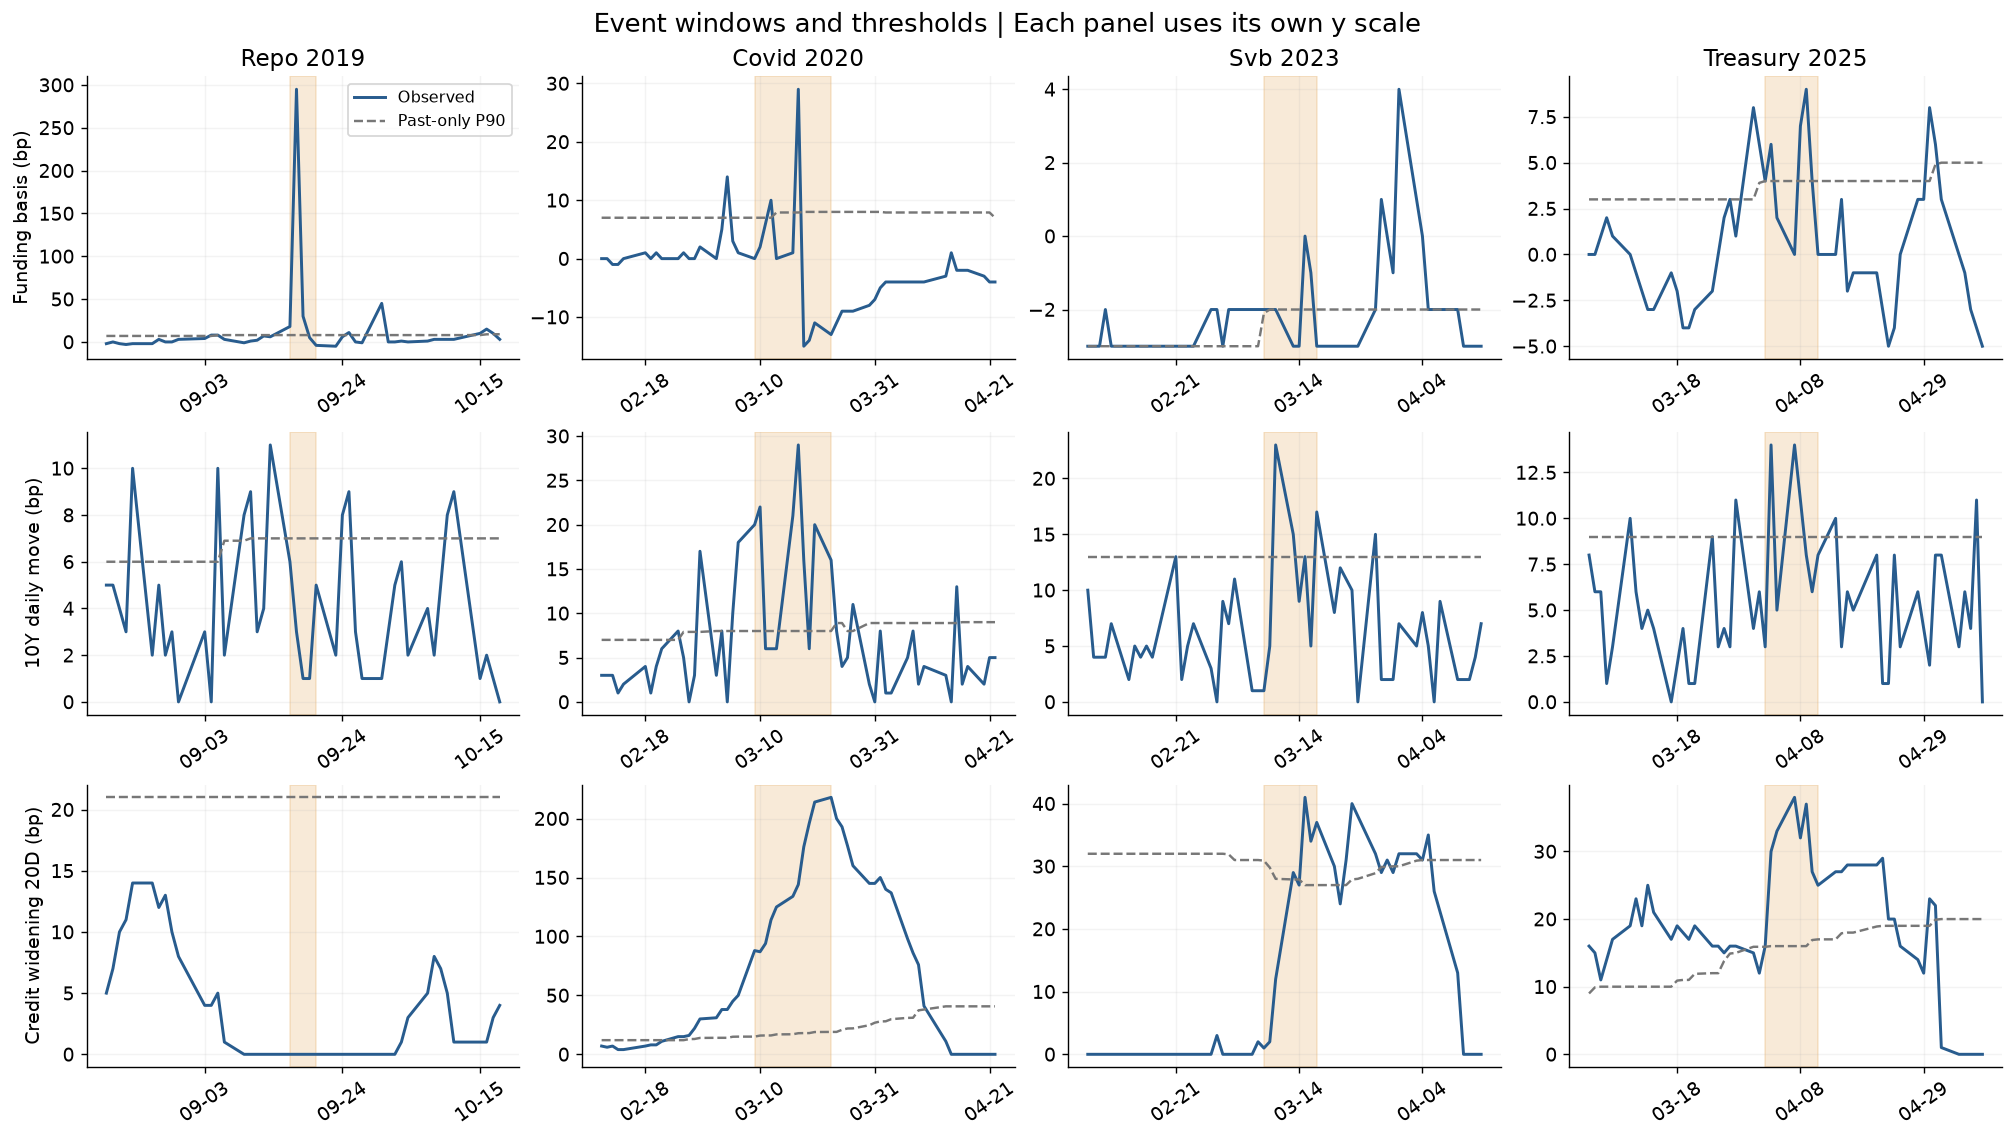

In [4]:
fig, axes = plt.subplots(3,4,figsize=(16,9),constrained_layout=True)
series = ['sofr_effr','ust10_abs_change','baa_widen20']
names = {'sofr_effr':'Funding basis (bp)','ust10_abs_change':'10Y daily move (bp)','baa_widen20':'Credit widening 20D (bp)'}
for col, ev in enumerate(plan['event_windows']):
    start,end=pd.Timestamp(ev['start']),pd.Timestamp(ev['end'])
    for row,ind in enumerate(series):
        ax=axes[row,col]; s=daily[(daily.indicator==ind)&daily.date.between(start-pd.Timedelta(days=30),end+pd.Timedelta(days=30))]
        ax.plot(s.date,s.value,color='#285c8e',lw=1.7,label='Observed')
        ax.plot(s.date,s.threshold_past90,color='#777777',ls='--',lw=1.4,label='Past-only P90')
        ax.axvspan(start,end,color='#db8e28',alpha=.18)
        ax.set_title(ev['id'].replace('_',' ').title() if row==0 else '')
        if col==0: ax.set_ylabel(names[ind])
        ax.tick_params(axis='x',rotation=35)
        ax.xaxis.set_major_locator(plt.matplotlib.dates.WeekdayLocator(interval=3))
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m-%d'))
        if row==0 and col==0: ax.legend(fontsize=9)
fig.suptitle('Event windows and thresholds | Each panel uses its own y scale',fontsize=15)
fig.savefig(ROOT/'figures/event_windows.png',dpi=150,bbox_inches='tight'); plt.show()

SOFR−EFFR 在 2019-09-17 为 **295bp**，不是截图示例的 30bp。SVB 窗口的原始利差峰值为 **0bp**：它因自身历史阈值较低而报警，不能称为严重回购资金短缺。COVID 资金利差仅在约 18.2% 的事件日报警。事件“通过”只代表满足这一版相对阈值规则。

VIX、Baa 利差水平、20 日收益率波动没有在 SVB 预定窗口高于自己的过去第 90 百分位，因此按规则不通过；指标和数据仍全部保留。

In [5]:
q = analysis.quarter_stress(daily)
corrs, combined, pairs = analysis.correlations(q,pqd,event_screen)
supplemental = analysis.supplemental_tests(q,pqd)
summary = corrs[corrs['sample']=='selection'].pivot(index='indicator',columns='entity',values='rho')
display(summary.round(3))
display(combined[['entity','indicator','n_pairs','rho','block_ci95_low','block_ci95_high','both_gates_pass','selected_in_channel','research_weight']].round(3))

entity,GSD,MBSD,NSCC
indicator,,,
baa_spread,0.438,-0.245,-0.685
baa_widen20,-0.242,-0.040,-0.379
sofr_effr,-0.093,0.083,0.355
sofr_effr_adjusted,-0.003,-0.015,0.332
ust10_abs_change,-0.480,-0.339,-0.025
ust10_rv20,-0.603,-0.179,0.002
vix,0.402,-0.436,-0.520


,entity,indicator,n_pairs,rho,block_ci95_low,block_ci95_high,both_gates_pass,selected_in_channel,research_weight
0,GSD,sofr_effr,16,-0.093,-0.813,0.136,False,False,0.0
1,MBSD,sofr_effr,16,0.083,-0.189,0.515,False,False,0.0
2,NSCC,sofr_effr,16,0.355,-0.335,0.560,True,True,1.0
3,GSD,sofr_effr_adjusted,16,-0.003,-0.789,0.172,False,False,0.0
4,MBSD,sofr_effr_adjusted,16,-0.015,-0.262,0.498,False,False,0.0
5,NSCC,sofr_effr_adjusted,16,0.332,-0.450,0.511,True,False,0.0
6,GSD,ust10_abs_change,17,-0.480,-0.662,0.406,False,False,0.0
7,MBSD,ust10_abs_change,17,-0.339,-0.695,-0.119,False,False,0.0
8,NSCC,ust10_abs_change,17,-0.025,-0.795,0.239,False,False,0.0
9,GSD,ust10_rv20,17,-0.603,-0.792,0.119,False,False,0.0


## 检验二：与下一季度 PQD 的关系

下面画筛选期相关系数及 95% 四季度连续区块 bootstrap 区间（2,000 次）；抽样区块不跨越缺失季度。rho ≥0.3 的虚线是初筛门槛，不是统计显著性标准。样本资金通道 16 对，其余 17 对；后续验证仅 6 对。

全样本相关、原始 p、BH 多重校正、循环位移参考、季度差分和同比差分均保存在 CSV。普通 p 不处理序列依赖；循环位移只有 n 个不同对齐方式，在筛选样本中达不到 5% 的最小 p 分辨率，所以不把它作为唯一淘汰依据。

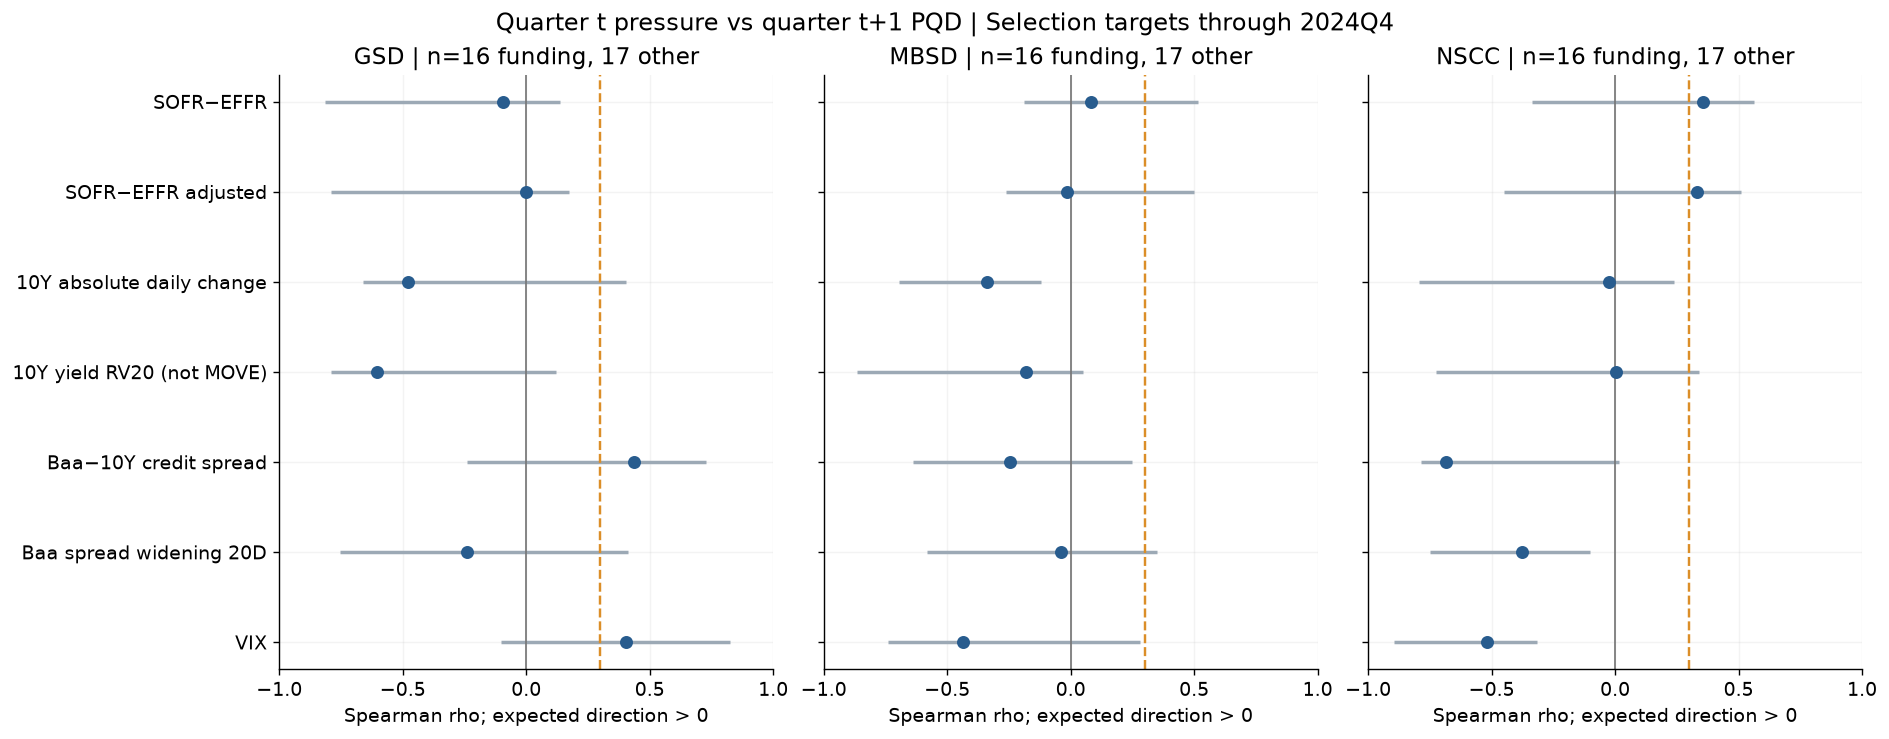

In [6]:
fig, axes = plt.subplots(1,3,figsize=(15,5.8),sharex=True,sharey=True,constrained_layout=True)
inds = [m['indicator'] for m in analysis.METRICS]
labels = [m['label'] for m in analysis.METRICS]
for ax,entity in zip(axes,['GSD','MBSD','NSCC']):
    s=corrs[(corrs.entity==entity)&(corrs['sample']=='selection')].set_index('indicator').loc[inds]
    y=np.arange(len(inds)); ax.hlines(y,s.block_ci95_low,s.block_ci95_high,color='#9ca9b5',lw=2)
    ax.scatter(s.rho,y,color='#285c8e',s=42,zorder=3)
    ax.axvline(0,color='#777',lw=1); ax.axvline(.3,color='#db8e28',ls='--',lw=1.4)
    ax.set_title(f'{entity} | n=16 funding, 17 other')
    ax.set_xlabel('Spearman rho; expected direction > 0'); ax.set_xlim(-1,1)
    ax.set_xticks([-1,-.5,0,.5,1]); ax.set_yticks(y,labels)
axes[0].invert_yaxis()
fig.suptitle('Quarter t pressure vs quarter t+1 PQD | Selection targets through 2024Q4',fontsize=14)
fig.savefig(ROOT/'figures/pqd_correlations_ci.png',dpi=150,bbox_inches='tight');plt.show()

两项初筛同时通过的是 NSCC 两个资金利差候选。它们的区间都跨零，BH 校正后 q≈0.386 / 0.398；季度差分关系为负，不能宣布传导已验证。按筛选期系数机械排序暂选原始利差（0.355 vs 0.332），差异很小，不能证明它更好。CSV 中该候选权重 1 只表示“唯一选出的候选通道”，**不是 NSCC 总风险全部来自资金通道**。

GSD 与 MBSD 保留原始候选并标记待解释，没有依据这些失败结果断言“利率冲击无影响”。

## 上一期 PQD 脆弱度与发布时点

资金脆弱度=支付义务/已量化资源；利率脆弱度=超过保证金的 Cover1 压力损失/保证金；信用脆弱度=前五会员持仓份额。外部压力转为仅相对于严格过去季度的 0–1 中位秩百分位，再乘脆弱度。

比例的数值尺度不同，**不跨通道比较或直接加总**；0 的乘积表示所用相对指标在观察历史底部，不表示业务无风险。完整季度最大值只有季度末才能计算。

2026Q1 PQD 在目录列示为 2026-05-28：2026Q2 开始时尚不可用，季度末时已列示。表中同时保留上一期版本和季度开始可用报告版本；列示日期只是首次公开日期的代理。

In [7]:
vulnerability = analysis.vulnerabilities(q,pqd)
snapshots = analysis.event_vulnerability_snapshots(daily,pqd)
display(vulnerability[(vulnerability.quarter=='2026Q2')&vulnerability.indicator.isin(['sofr_effr','ust10_abs_change','baa_spread'])][['entity','channel','prior_vulnerability','prior_listed_date','prior_report_available_at_quarter_start_proxy','availability_proxy_quarter']].round(4))
display(snapshots[(snapshots.event=='svb_2023')&snapshots.indicator.eq('ust10_abs_change')][['entity','event_date','latest_report_available_proxy','vulnerability','observed_daily_value','product_research_only']].round(4))

,entity,channel,prior_vulnerability,prior_listed_date,prior_report_available_at_quarter_start_proxy,availability_proxy_quarter
63,GSD,credit,0.2746,2026-05-28,False,2025Q4
64,MBSD,credit,0.4812,2026-05-28,False,2025Q4
65,NSCC,credit,0.3711,2026-05-28,False,2025Q4
195,GSD,funding,0.7803,2026-05-28,False,2025Q4
196,MBSD,funding,0.2049,2026-05-28,False,2025Q4
197,NSCC,funding,0.9962,2026-05-28,False,2025Q4
327,GSD,rates,0.0467,2026-05-28,False,2025Q4
328,MBSD,rates,0.2407,2026-05-28,False,2025Q4
329,NSCC,rates,0.0910,2026-05-28,False,2025Q4


,entity,event_date,latest_report_available_proxy,vulnerability,observed_daily_value,product_research_only
48,GSD,2023-03-10,2022Q4,0.0856,23.0,0.0846
49,MBSD,2023-03-10,2022Q4,0.3111,23.0,0.3074
50,NSCC,2023-03-10,2022Q4,0.2446,23.0,0.2417


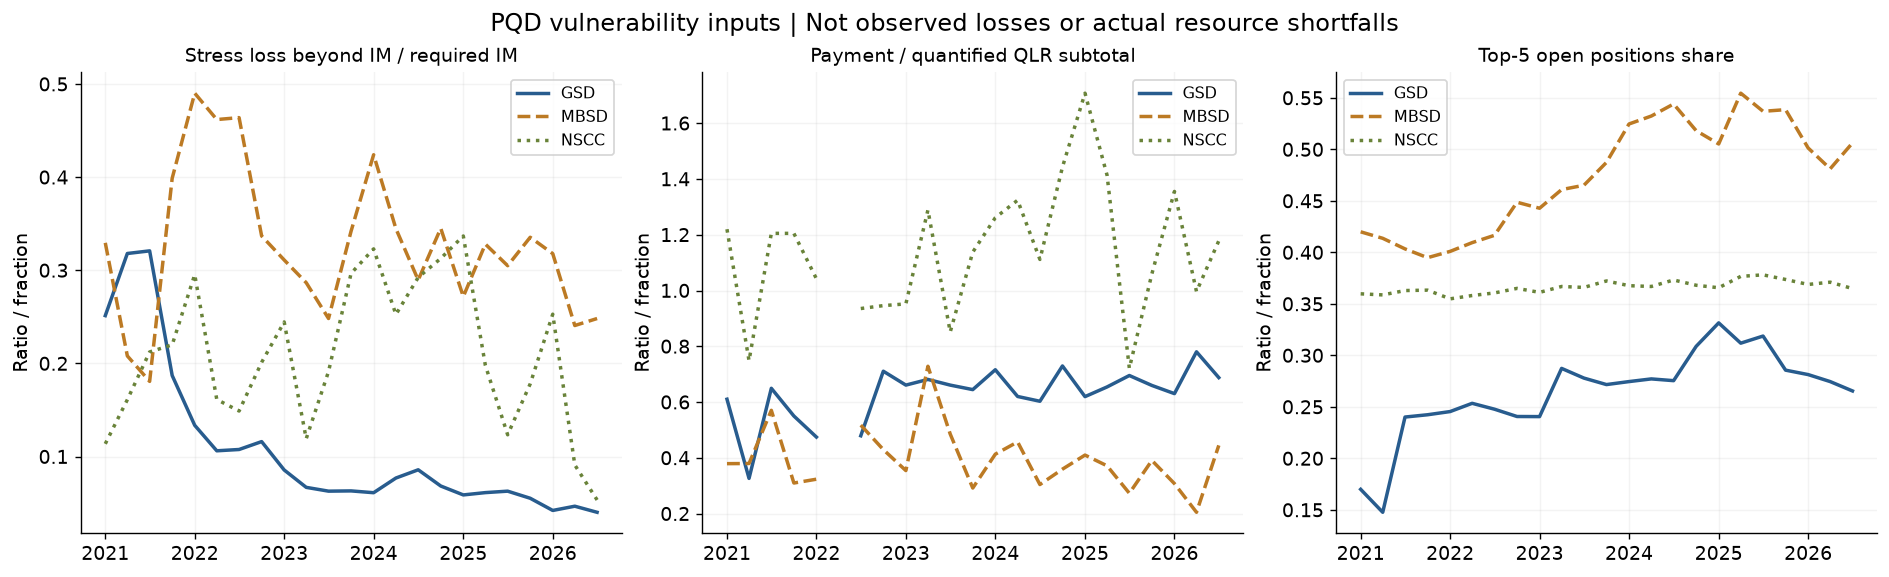

In [8]:
fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
styles={'GSD':('#285c8e','-'),'MBSD':('#bc7a24','--'),'NSCC':('#698339',':')}
cols=[('stress_loss_to_im','Stress loss beyond IM / required IM'),('payment_to_qlr','Payment / quantified QLR subtotal'),('top5_open_share','Top-5 open positions share')]
for ax,(metric,title) in zip(axes,cols):
    for e,(color,ls) in styles.items():
        s=pqd[pqd.entity==e]; dates=pd.PeriodIndex(s.quarter,freq='Q').to_timestamp(how='end')
        ax.plot(dates,s[metric],label=e,color=color,ls=ls,lw=2)
    ax.set_title(title,fontsize=11); ax.set_ylabel('Ratio / fraction'); ax.legend(fontsize=9)
    ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y'))
fig.suptitle('PQD vulnerability inputs | Not observed losses or actual resource shortfalls',fontsize=14)
fig.savefig(ROOT/'figures/pqd_vulnerability_history.png',dpi=150,bbox_inches='tight');plt.show()

## 乘法结构和反常相关的解释性诊断

另算同季度对照、损失金额/保证金分解、以及“外部压力单独 / 上期脆弱度单独 / 两者相乘”。这些比较用于检查口径与持续性，**不回头替换筛选目标**。未来需要新样本检验修改后的模型。

NSCC 校正资金利差乘积在后续 6 期相关 −0.143；同一可比较样本的外部压力单独为 0.371。不能说乘积改善了模型。GSD 的下一季度损失比相关从筛选期 −0.480 到全样本 0.004，说明关系对时期和口径敏感；尚未确定反常方向的原因。

In [9]:
decomposition, interactions = analysis.transmission_diagnostics(q,pqd,vulnerability)
display(interactions[(interactions.entity=='NSCC')&(interactions.indicator=='sofr_effr_adjusted')][['sample','index_form','n','rho_with_next_outcome']].round(3))
display(decomposition[(decomposition.entity=='GSD')&(decomposition.indicator=='ust10_abs_change')&(decomposition['sample']=='selection')][['outcome','lag','n','rho']].round(3))

,sample,index_form,n,rho_with_next_outcome
45,selection,external_only,10,0.394
46,selection,prior_vulnerability_only,10,0.333
47,selection,external_times_prior,10,0.430
48,historical_validation,external_only,6,0.371
49,historical_validation,prior_vulnerability_only,6,-0.257
50,historical_validation,external_times_prior,6,-0.143
51,all,external_only,16,0.359
52,all,prior_vulnerability_only,16,-0.009
53,all,external_times_prior,16,0.038


,outcome,lag,n,rho
96,cover1_stress_loss_beyond_im_usd,0,17,-0.531
97,initial_margin_required_usd,0,17,0.254
98,stress_loss_to_im,0,17,-0.291
114,cover1_stress_loss_beyond_im_usd,1,17,-0.431
115,initial_margin_required_usd,1,17,0.358
116,stress_loss_to_im,1,17,-0.480


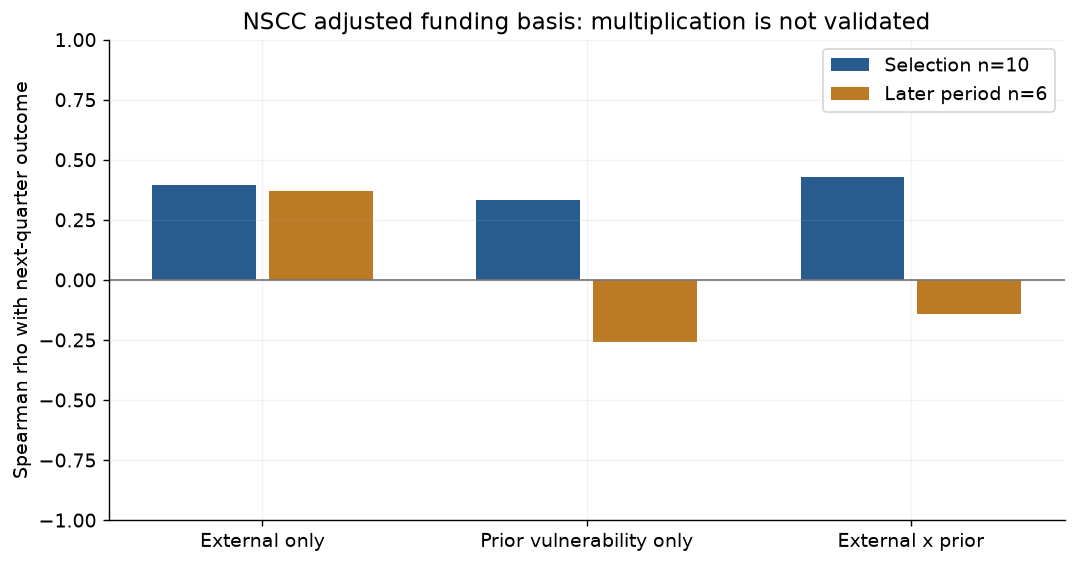

In [10]:
fig,ax=plt.subplots(figsize=(8.5,4.4),constrained_layout=True)
s=interactions[(interactions.entity=='NSCC')&(interactions.indicator=='sofr_effr_adjusted')&interactions['sample'].isin(['selection','historical_validation'])]
forms=['external_only','prior_vulnerability_only','external_times_prior']; labels=['External only','Prior vulnerability only','External x prior']
for offset,(sample,color,label) in zip([-.18,.18],[('selection','#285c8e','Selection n=10'),('historical_validation','#bc7a24','Later period n=6')]):
    z=s[s['sample']==sample].set_index('index_form').loc[forms]
    ax.bar(np.arange(3)+offset,z.rho_with_next_outcome,width=.32,color=color,label=label)
ax.axhline(0,color='#777',lw=1);ax.set_ylim(-1,1);ax.set_ylabel('Spearman rho with next-quarter outcome')
ax.set_xticks(np.arange(3),labels);ax.legend();ax.set_title('NSCC adjusted funding basis: multiplication is not validated')
fig.savefig(ROOT/'figures/interaction_validation.png',dpi=150,bbox_inches='tight');plt.show()

## 完成情况与边界

实际覆盖不足天数单独保留：GSD 流动性覆盖不足天数全为零，无法据此计算有意义的相关；MBSD 和 NSCC 有少量非零。三家信用资源超出天数都没有变化。此处的 backtest 不足不是实际违约损失。

下一步数据重点：更早的季度 PQD、明确的首次发布日期/原始历史版本、合法可用的 MOVE 日度历史、MBSD 的 MBS 价格/利差/提前还款冲击指标，以及日度业务保证金与支付义务。公开 PQD 本身无法证实某事件实际造成 DTCC 损失。

方法参考：本地 Quant_tech《Machine Learning 3》的分类评估/过拟合内容与 skill 的时间序列验证规则；业务字段以 DTCC PQD 和 2026Q2 FICC Disclosure Framework 为准。

来源与采集：PQD 和四条旧日度输入从 2026-10-05 冻结文件复用；本轮 BAA10Y 与 FICC Framework 于 2026-10-06 取得，具体 UTC 时间和哈希见 `source_manifest.json`。当前版本可能包含历史修订，不代表当时可获取的版本。

In [11]:
audit = analysis.audit(pqd,daily,q,pairs)
display(pd.DataFrame([{'check':'PQD periods','result':audit['pqd_quarters']},
    {'check':'Entity-quarter rows','result':audit['pqd_entity_quarter_rows']},
    {'check':'Daily indicators','result':audit['daily_indicators']},
    {'check':'Source files hash checked','result':audit['source_hashes_verified']},
    {'check':'Repo event SOFR-EFFR (bp)','result':audit['repo_2019_09_17_basis_bp']}]))
print('Audited CSV tables, plots and validation_audit.json saved under this notebook folder.')

,check,result
0,PQD periods,23.0
1,Entity-quarter rows,69.0
2,Daily indicators,7.0
3,Source files hash checked,29.0
4,Repo event SOFR-EFFR (bp),295.0


Audited CSV tables, plots and validation_audit.json saved under this notebook folder.
